In [1]:
from rdkit import Chem
import pickle
import os
import json
import numpy as np
import xgboost

from shared.ml_helper import make_fingerprint # pyright: ignore[reportMissingImports]
from matplotlib import pyplot as plt
from cycler import cycler

from matplotlib.colors import ListedColormap
import numpy as np

# Example: define your own RGB color palette
# Replace these tuples with your desired RGB codes (values between 0 and 1)
custom_colors = [
    (169, 27, 46),  # blue-ish
    (0, 138, 173),  # red-ish
    (0, 48, 136),  # green-ish
    (138, 26, 155),  # yellow-ish
    (240, 137, 0)   # purple-ish
]

custom_c = [ tuple(c[i] / 256.0 for i in range(3)) for c in custom_colors ]

custom_cmap = ListedColormap(custom_c)
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}

In [2]:
# Data analysis



arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: '-H+ to bond',
    9: '-H+ to atom',
    10: 'elimination to bond'
}


training_dir = "training_sets/20260202"


# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors = []
outcomes = []
contributors = {}
count_dirs = 0
count_arrows = 0

# open("bitvector_origins.txt", "w").close()

for subdir in subdirs:
    count_dirs += 1
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {pkl_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    contributor = data.get('contributor')
    if contributor in contributors or None in contributors:
        if contributor == '':
             contributors[None] += 1
        else:
            contributors[contributor] += 1
    else:
        if contributor == '':
             contributors[None] = 1
        else:
            contributors[contributor] = 1
    for id, info in choices.items():
        # bitvector for the mechanism
        if info['probable'] is None:
            continue
        try:
            sum_finger_print = make_fingerprint(sm, info['mechanism'], elim=True)
        except:
             print(f"Error processing {training_dir}/{subdir} mechanism {info['mechanism']}")
        bitvectors.append(sum_finger_print)
        
        count_arrows += 1
        outcomes.append(info['probable'])
        # Track the origin of each bitvector
        # with open("bitvector_origins.txt", "a") as origin_file:
        #     origin_file.write(f"{len(bitvectors)-1},{training_dir}/{subdir},{id}\n")


print(f"total directories: {count_dirs}, total arrows: {count_arrows}")
# with open(f'{training_dir}/bitvectors.csv', 'w', newline='') as csvfile:
#     writer = csv.writer(csvfile)
#     for bv, outcome in zip(bitvectors, outcomes):
#         writer.writerow(bv + [outcome])

total directories: 396, total arrows: 9355


In [ ]:
set_bitvectors = set(tuple(bv) for bv in bitvectors)
print(f"Total unique bitvectors: {len(set_bitvectors)}")
print(f"Total bitvectors: {len(bitvectors)}")


Total unique bitvectors: 6247
Total bitvectors: 9355


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, recall_score, precision_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay, auc

In [6]:
from xgboost import XGBClassifier

In [19]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

ratio = len(outcomes)/sum(outcomes)
print(ratio)

# XGBoost Regression classifier
clf = XGBClassifier(scale_pos_weight = 7, eval_metric='logloss', max_depth=10)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
model_dir = "models/v130"
# os.makedirs(model_dir, exist_ok=True)
# clf.save_model(os.path.join(model_dir, "xg_model_elim.json"))
#joblib.dump(clf, 'models/v13/xg_model.pkl')
#clf.save_model('models/v81/xg_model.json')

6.639460610361959
              precision    recall  f1-score   support

           0       0.97      0.96      0.97      1983
           1       0.79      0.85      0.82       356

    accuracy                           0.94      2339
   macro avg       0.88      0.90      0.89      2339
weighted avg       0.94      0.94      0.94      2339



In [18]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

sample_weight = []

for i in range(len(X_train)):
    if X_train[i][8] == 1 or X_train[i][9] == 1:
        if y_train[i] == 1:
            sample_weight.append(70)
        else:
            sample_weight.append(10)
    else:
        if y_train[i] == 1:
            sample_weight.append(7)
        else:
            sample_weight.append(1)

ratio = len(outcomes)/sum(outcomes)
print(ratio)

# XGBoost Regression classifier
clf = XGBClassifier( eval_metric='logloss', max_depth=10)
clf.fit(X_train, y_train, sample_weight=sample_weight)

# Predict
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
model_dir = "models/v130"
# os.makedirs(model_dir, exist_ok=True)
# clf.save_model(os.path.join(model_dir, "xg_model_elim.json"))
#joblib.dump(clf, 'models/v13/xg_model.pkl')
#clf.save_model('models/v81/xg_model.json')

6.639460610361959
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      2001
           1       0.78      0.89      0.83       338

    accuracy                           0.95      2339
   macro avg       0.88      0.92      0.90      2339
weighted avg       0.95      0.95      0.95      2339



In [20]:
X_elim_test = []
y_elim_test = []
for i, bv in enumerate(X_test):
    if bv[8] == 1 or bv[9] == 1:
        X_elim_test.append(bv)
        y_elim_test.append(y_test[i])

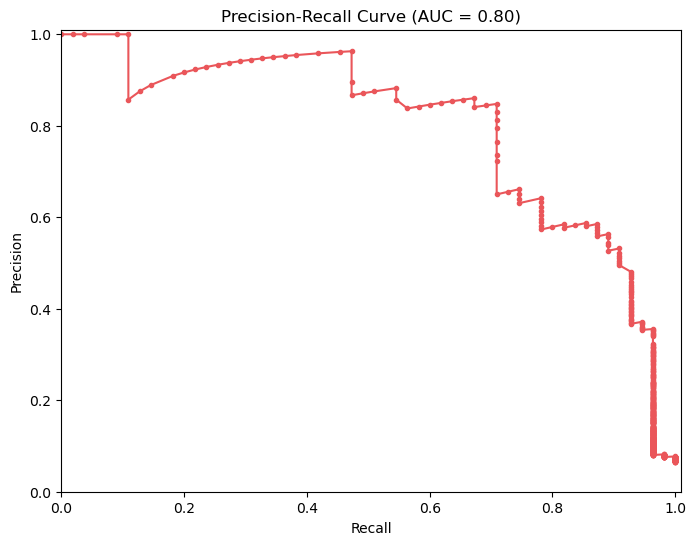

In [21]:
# Make predictions on the test set


# clf = XGBClassifier()
# clf.load_model("models/v130/xg_model_elim.json")
y_pred = clf.predict_proba(X_elim_test)[:, 1]
 
# Calculate precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_elim_test, y_pred)
 
# Calculate the area under the PR curve
auc_score = auc(recall, precision)
 
# Plot the Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', label='PR Curve', color='#ea565aff')
plt.xlim(0, 1.01)
plt.ylim(0, 1.01)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.show()
#plt.savefig('pr_curve_3.svg')
 

In [45]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

model = XGBClassifier(
    eval_metric="aucpr",
    random_state=42,
    scale_pos_weight =7
)

param_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, 12]
}

cv = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="average_precision",   # or accuracy, neg_log_loss, etc.
    cv=5,
    n_jobs=-1,
    verbose=1
    
)

cv.fit(X_train, y_train)

print("Best max_depth:", cv.best_params_["max_depth"])
print("Best CV score:", cv.best_score_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits


Best max_depth: 8
Best CV score: 0.8586085154568514


In [22]:
with open("models/v114/split_data.pkl", "rb") as f:
    split_meta = pickle.load(f)
split_meta["groups"]

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39,
 40,
 41,
 42,
 43,
 44,
 45,
 46,
 47,
 48,
 49,
 50,
 51,
 52,
 53,
 54,
 55,
 56,
 57,
 58,
 59,
 60,
 61,
 62,
 63,
 64,
 65,
 66,
 67,
 68,
 69,
 70,
 71,
 72,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 80,
 81,
 82,
 83,
 84,
 85,
 86,
 21,
 87,
 88,
 89,
 90,
 91,
 92,
 93,
 94,
 95,
 96,
 97,
 98,
 99,
 100,
 101,
 102,
 103,
 104,
 105,
 106,
 107,
 42,
 108,
 109,
 110,
 111,
 112,
 113,
 114,
 115,
 116,
 87,
 117,
 118,
 119,
 93,
 120,
 121,
 97,
 122,
 123,
 124,
 125,
 126,
 127,
 128,
 58,
 129,
 130,
 131,
 132,
 121,
 133,
 134,
 135,
 136,
 137,
 138,
 139,
 140,
 141,
 142,
 143,
 144,
 145,
 146,
 147,
 148,
 149,
 150,
 151,
 152,
 153,
 154,
 155,
 156,
 157,
 158,
 159,
 160,
 161,
 162,
 58,
 163,
 164,
 165,
 166,
 167,
 168,
 169,
 170,
 171,
 172,
 173,
 174,
 175,
 176,
 177,
 

In [ ]:
# Define a function to calculate evaluation metrics for a given threshold
def evaluate_threshold(y_true, y_pred_proba, threshold):
    y_pred = (y_pred_proba >= threshold).astype(int)
    precision, recall, _ = precision_recall_curve(y_true, y_pred)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-7)
    balanced_accuracy = (recall[1] + recall[0]) / 2
    print("     precision    recall   f1-score ")
    print(f"0     {precision[0]:.4f}       {recall[0]:.4f}      {f1[0]:.4f}")
    print(f"1     {precision[1]:.4f}       {recall[1]:.4f}      {f1[1]:.4f}")
    print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
    return precision, recall, f1, balanced_accuracy


In [150]:
evaluate_threshold(y_test, y_pred_proba, 0.3)

     precision    recalll   f1-score 
0     0.1150       1.0000      0.2062
1     0.5720       0.8614      0.6875
Balanced Accuracy: 0.9307


(array([0.11495845, 0.572     , 1.        ]),
 array([1.        , 0.86144578, 0.        ]),
 array([0.20621116, 0.68749995, 0.        ]),
 np.float64(0.9307228915662651))

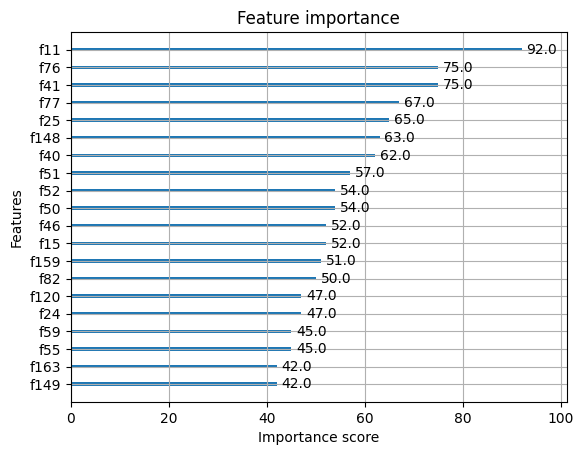

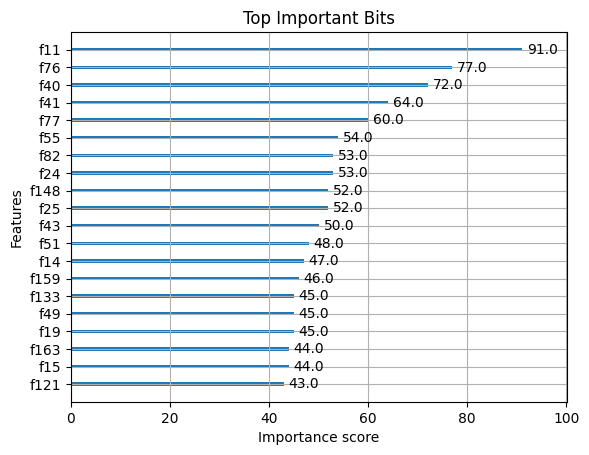

In [77]:
clf1 = XGBClassifier()
clf1.load_model('models/v14/xg_model.json')
clf2 = XGBClassifier()
clf2.load_model('models/v13/xg_model.json')
xgboost.plot_importance(clf1, max_num_features=20)
xgboost.plot_importance(clf2, max_num_features=20)
plt.title("Top Important Bits")
plt.show()

In [35]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)


clf = RandomForestClassifier(
    n_estimators=100,     # number of trees
    max_depth=None,       # let trees grow until pure
    class_weight='balanced',  # helpful for imbalanced classes
    random_state=42
)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9521531100478469
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.97      2381
           1       0.83      0.76      0.80       336

    accuracy                           0.95      2717
   macro avg       0.90      0.87      0.89      2717
weighted avg       0.95      0.95      0.95      2717



In [41]:
%run ml_tools/get_feature.py 10

Feature at index 10: Atom 1 - Charge Bit


In [ ]:
beckmann = Chem.MolFromSmiles('[OH2+]N=C1CCCCC1')
alkyl = Chem.MolFromSmiles('CC(C)(C)[CH2+]')
tert_brom = Chem.MolFromSmiles('CC1(Br)CCCCC1')
bv = Chem.MolFromSmiles('OOC1(O)CCCCC1')
bv_p = Chem.MolFromSmiles('[OH2+]OC1(O)CCCCC1')
r_aldol = Chem.MolFromSmiles('COC(C)([O-])C(C)(C)C(C)=O')
ohira_bestman = Chem.MolFromSmiles('CC(=[C])C1=CC=CC=C1')
diazo = Chem.MolFromSmiles('N#[N+]C1=CC=CC=C1')
brook = Chem.MolFromSmiles('CC(C[O-])[Si](C)(C)C')
benzoin = Chem.MolFromSmiles('N#CC([O-])(c1ccccc1)C(O)c1ccccc1')


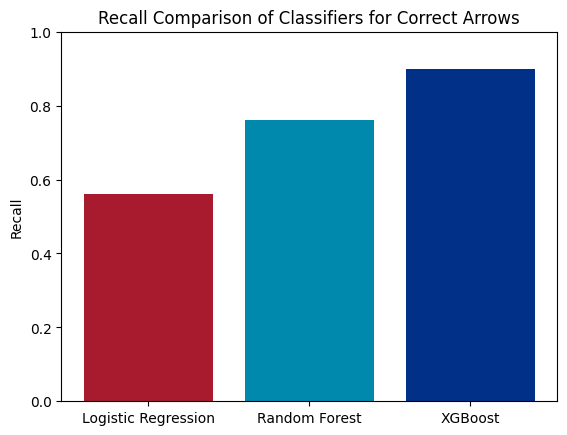

In [36]:
recalls = [0.56, 0.76, 0.90]
labels = ["Logistic Regression", "Random Forest", "XGBoost"]
plt.bar(labels, recalls, color=custom_c[:len(labels)])
plt.ylabel("Recall")
plt.title("Recall Comparison of Classifiers for Correct Arrows")
plt.ylim(0, 1)
plt.show()